In [1]:
from typing import List, Dict, Union
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from ccxt.binance import binance

from siglab_py.util.simple_math import bucket_series, bucketize_val
from siglab_py.util.market_data_util import fetch_candles
from siglab_py.util.analytic_util import compute_candles_stats

VALIDATION_MAX_GAPS = 30

In [ ]:
start_date = datetime(2021, 1,1)
end_date = datetime(2026,10,26,0,0,0)
exchange = binance()
candle_size = "1h"

ValueError: year 20261 is out of range

## Fetch Candles

In [ ]:
all_candles = {}
all_candles_w_ta = {}
all_orderbooks = {}
crypto_tickers = [ "BTC/USDT:USDT", "ETH/USDT:USDT", "SOL/USDT:USDT", "HYPE/USDT:USDT", "DOGE/USDT:USDT", "NEAR/USDT:USDT", "SUI/USDT:USDT", "XLM/USDT:USDT", "ZEC/USDT:USDT", "XMR/USDT:USDT", "TAO/USDT:USDT", "HBAR/USDT:USDT" ]
for ticker in crypto_tickers:
    candles = fetch_candles(
                                                    start_ts=int(start_date.timestamp()), 
                                                    end_ts=int(end_date.timestamp()), 
                                                    exchange=exchange, normalized_symbols=[ticker], 
                                                    candle_size = candle_size, 
                                                    num_candles_limit = 100,
                                                    validation_max_gaps = VALIDATION_MAX_GAPS, # some newly listed FX pairs gaps
                                                    logger = None
                                                )
    pd_candles = candles[ticker]
    all_candles[ticker] = pd_candles
    print(f"Done fetch candles for {ticker}")

    all_orderbooks[ticker] = exchange.fetch_order_book(symbol=ticker)
    all_orderbooks[ticker]['timestamp'] = all_orderbooks[ticker]['timestamp'] if all_orderbooks[ticker]['timestamp'] else datetime.now().timestamp() # in seconds

## Calculate TA

In [ ]:
for ticker in crypto_tickers:
    pd_candles = all_candles[ticker]
    compute_candles_stats(
            pd_candles=pd_candles,
            boillenger_std_multiples=2,
            sliding_window_how_many_candles=24,
            validation_max_gaps = VALIDATION_MAX_GAPS, # some newly listed FX pairs gaps
            pypy_compat=True
        )

    all_candles_w_ta[ticker] = pd_candles

    print(f"Done calculate TA for {ticker}")

# ADX

In [ ]:
focused = "SOL/USDT:USDT"
pd_candles = all_candles_w_ta[focused]
pd_candles

,exchange,symbol,timestamp_ms,datetime_utc,datetime,open,high,low,close,volume,...,macd_cross_last,macd_cross_open,macd_segment_id,macd_divergence,fib_0.618_short_periods,fib_0.618_long_periods,gap_close_vs_ema,gap_close_vs_ema_percent,close_above_or_below_ema,close_vs_ema_inflection
0,Lighter,SOL/USDC:USDC,1767196800000,2025-12-31 16:00:00+00:00,2026-01-01 00:00:00,125.562,125.719,124.379,124.843,126078.147,...,None,NaN,0,NaN,NaN,NaN,0.000000,0.000000,None,0.0
1,Lighter,SOL/USDC:USDC,1767200400000,2025-12-31 17:00:00+00:00,2026-01-01 01:00:00,124.843,125.261,124.565,125.040,49859.437,...,None,NaN,0,NaN,NaN,NaN,0.181240,0.144946,above,1.0
2,Lighter,SOL/USDC:USDC,1767204000000,2025-12-31 18:00:00+00:00,2026-01-01 02:00:00,125.040,125.500,124.529,124.699,157260.235,...,bearish,125.040,1,---,NaN,NaN,-0.146979,-0.117867,below,NaN
3,Lighter,SOL/USDC:USDC,1767207600000,2025-12-31 19:00:00+00:00,2026-01-01 03:00:00,124.699,125.232,124.397,124.398,190670.157,...,bearish,125.040,1,---,NaN,NaN,-0.412141,-0.331308,below,NaN
4,Lighter,SOL/USDC:USDC,1767211200000,2025-12-31 20:00:00+00:00,2026-01-01 04:00:00,124.398,124.952,123.684,124.257,142679.027,...,bearish,125.040,1,---,NaN,NaN,-0.508890,-0.409546,below,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6795,Lighter,SOL/USDC:USDC,1791658800000,2026-10-10 19:00:00+00:00,2026-10-11 03:00:00,110.359,110.687,110.305,110.511,52091.662,...,bullish,109.057,654,hidden_bearish_divergence,110.004240,109.532088,0.521542,0.471937,above,NaN
6796,Lighter,SOL/USDC:USDC,1791662400000,2026-10-10 20:00:00+00:00,2026-10-11 04:00:00,110.511,110.567,110.298,110.357,22696.297,...,bullish,109.057,654,hidden_bearish_divergence,110.110536,109.541976,0.338139,0.306404,above,NaN
6797,Lighter,SOL/USDC:USDC,1791666000000,2026-10-10 21:00:00+00:00,2026-10-11 05:00:00,110.357,110.480,110.191,110.305,13817.898,...,bullish,109.057,654,hidden_bearish_divergence,110.134638,109.612428,0.263248,0.238654,above,NaN
6798,Lighter,SOL/USDC:USDC,1791669600000,2026-10-10 22:00:00+00:00,2026-10-11 06:00:00,110.305,110.560,110.221,110.478,19344.150,...,bullish,109.057,654,hidden_bearish_divergence,110.134638,109.612428,0.401348,0.363283,above,1.0


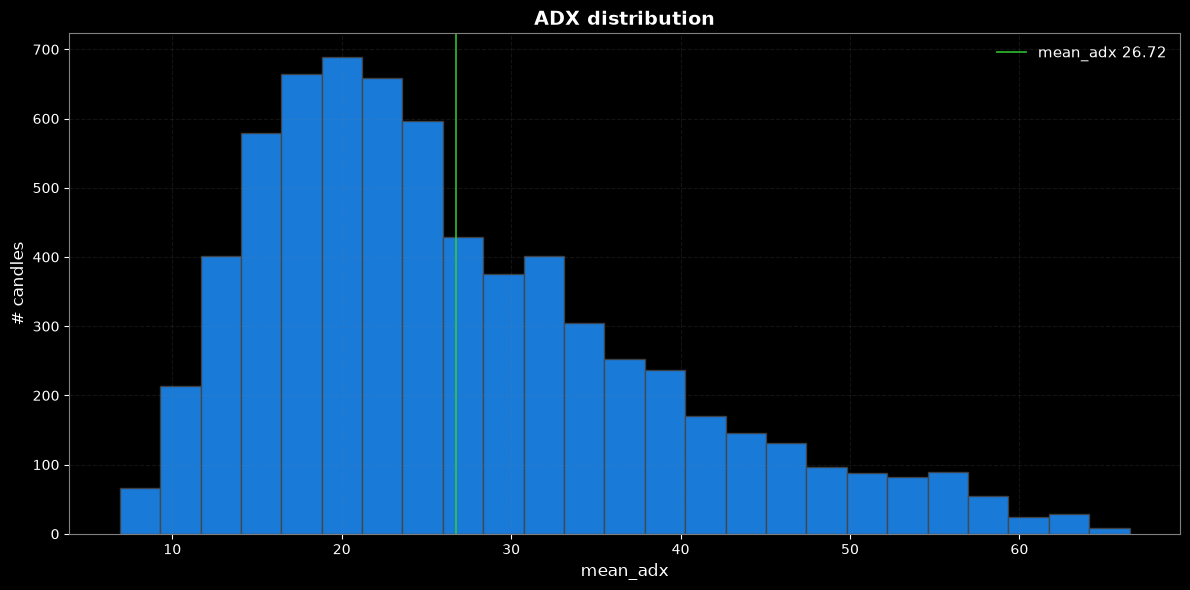

In [ ]:
plt.figure(figsize=(12, 6), facecolor='black')
ax = plt.gca()
ax.set_facecolor('black')

plt.hist(
    pd_candles['adx'],
    bins=25,
    edgecolor='#444444',
    alpha=0.85,
    color='dodgerblue'
)

mean_adx = round(pd_candles['adx'].mean(), 2)
plt.axvline(mean_adx, color='limegreen', linestyle='-', linewidth=1.3, alpha=0.85,
            label=f'mean_adx {mean_adx}')

plt.title('ADX distribution', 
          fontsize=14, fontweight='bold', color='white')
plt.xlabel('mean_adx', fontsize=12, color='white')
plt.ylabel('# candles', fontsize=12, color='white')

plt.grid(True, alpha=0.15, linestyle='--', color='gray')
plt.legend(loc='upper right', frameon=False, fontsize=10.5, labelcolor='white')

ax.tick_params(colors='white', which='both')
ax.spines['bottom'].set_color('gray')
ax.spines['top'].set_color('gray')
ax.spines['left'].set_color('gray')
ax.spines['right'].set_color('gray')

plt.tight_layout()
plt.show()

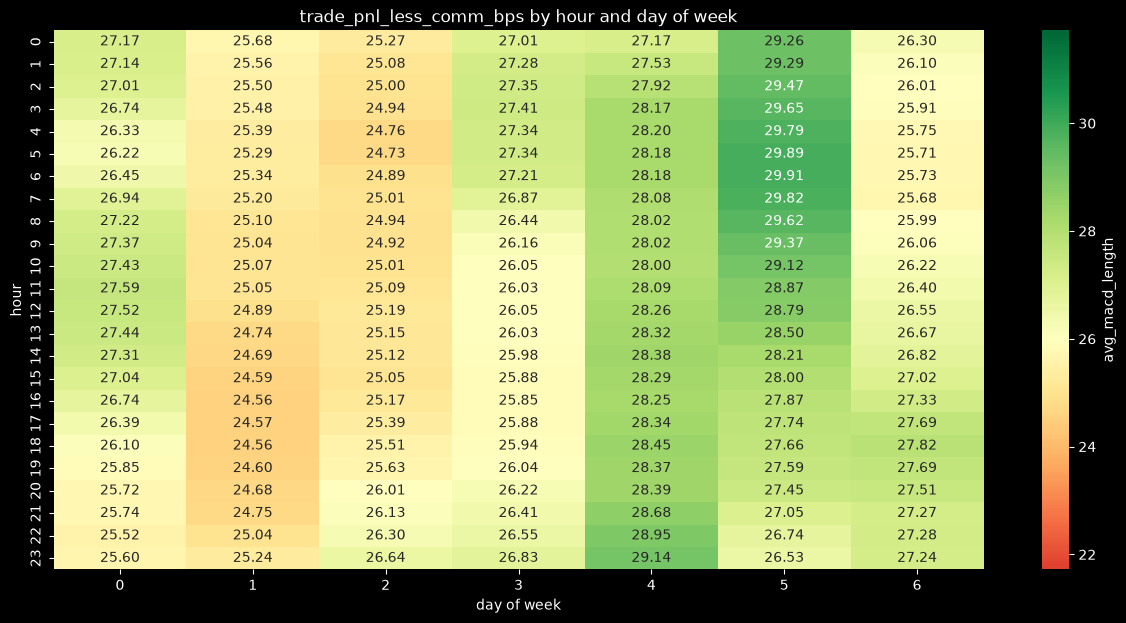

In [ ]:
grouped = pd_candles.groupby(['hour', 'dayofweek']).agg(
    mean_adx=('adx', 'mean'),
).reset_index()

heatmap_data = grouped.pivot(index='hour', columns='dayofweek', values='mean_adx')

plt.figure(figsize=(15, 7), facecolor='black')
ax = plt.gca()
ax.set_facecolor('black')

sns.heatmap(
    heatmap_data, 
    annot=True, 
    fmt='.2f', 
    cmap='RdYlGn', 
    vmin=mean_adx-5,
    vmax=mean_adx+5,
    center=26,
    cbar_kws={'label': 'mean_adx by hour and day of week'}
)

ax.set_title('trade_pnl_less_comm_bps by hour and day of week', color='white')
ax.set_xlabel('day of week', color='white')
ax.set_ylabel('hour', color='white')
ax.tick_params(colors='white')
cbar = ax.collections[0].colorbar
cbar.set_label('avg_macd_length', color='white')
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='white')

plt.show()

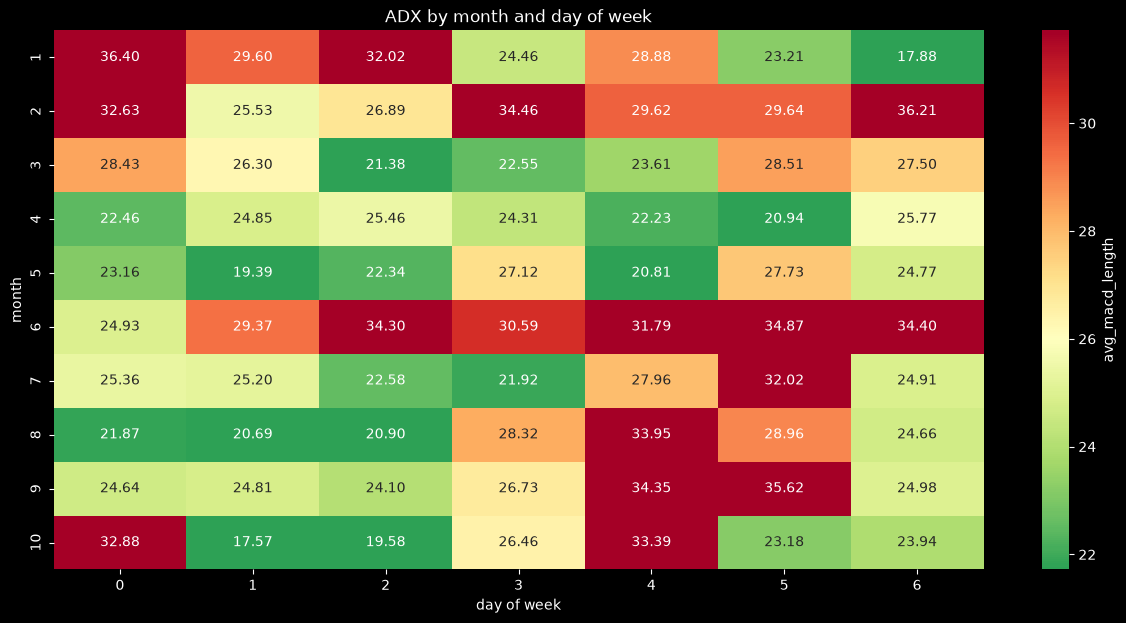

In [ ]:
grouped = pd_candles.groupby(['month', 'dayofweek']).agg(
    mean_adx=('adx', 'mean'),
).reset_index()

heatmap_data = grouped.pivot(index='month', columns='dayofweek', values='mean_adx')

plt.figure(figsize=(15, 7), facecolor='black')
ax = plt.gca()
ax.set_facecolor('black')

sns.heatmap(
    heatmap_data, 
    annot=True, 
    fmt='.2f', 
    cmap='RdYlGn_r', 
    vmin=mean_adx-5,
    vmax=mean_adx+5,
    center=26,
    cbar_kws={'label': 'mean_adx by month and day of week'}
)

ax.set_title('ADX by month and day of week', color='white')
ax.set_xlabel('day of week', color='white')
ax.set_ylabel('month', color='white')
ax.tick_params(colors='white')
cbar = ax.collections[0].colorbar
cbar.set_label('avg_macd_length', color='white')
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='white')

plt.show()